# Predicting Diabetes Risk from Health Survey Data

**Sushanth Yarlagadda**, ITCS 3156-002 Introduction to Machine Learning, UNC Charlotte, Fall 2026
(Instructor: Dr. Srinivas Akella)

This notebook contains the full machine learning workflow for the course project:

1. Data ingestion
2. Exploratory data analysis
3. Cleaning and preprocessing
4. Models
5. Training and tuning
6. Test set evaluation
7. Interpretation
8. Additional experiments
9. Conclusions

**Task.** Binary classification. Predict whether a person has prediabetes or diabetes (label 1)
or neither (label 0) from 21 answers to the CDC's 2015 Behavioral Risk Factor Surveillance
System (BRFSS) survey.

**Models.** Logistic Regression, Gaussian Naive Bayes, and K-Nearest Neighbors, compared against
a majority-class baseline. The test set is used once, at the end.

Running all cells from top to bottom reproduces every number in the report. `RANDOM_STATE = 42`
fixes every random choice. Only the timing values change from run to run.

## 0. Setup

Imports, constants, and the plot style used in every figure.

In [1]:
import os
import platform
import time
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from IPython.display import display
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, confusion_matrix, f1_score,
    precision_recall_curve, precision_score, recall_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import (
    GridSearchCV, StratifiedKFold, cross_val_score, learning_curve, train_test_split,
)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# joblib tries to count physical CPU cores with a Windows tool (wmic) that newer Windows
# versions no longer include, and prints a long warning. Setting the core count directly
# (half the logical cores, the usual physical count) skips that check. Results do not change.
os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(max(1, (os.cpu_count() or 2) // 2)))

RANDOM_STATE = 42
TARGET = "Diabetes_binary"
TEST_SIZE, VAL_SIZE = 0.15, 0.15   # 70/15/15 split
BMI_CLIP_PERCENTILE = 99.5         # BMI is clipped at this percentile of the training set
KNN_TUNE_ROWS = 40_000             # KNN is tuned on a subsample of train (full CV is too slow)

# Set to True to also save every figure as a PNG in ./figures (used to build the report).
SAVE_FIGURES = False
FIG_DIR = Path("figures")

BINARY = ["HighBP", "HighChol", "CholCheck", "Smoker", "Stroke", "HeartDiseaseorAttack",
          "PhysActivity", "Fruits", "Veggies", "HvyAlcoholConsump", "AnyHealthcare",
          "NoDocbcCost", "DiffWalk", "Sex"]
ORDINAL = ["GenHlth", "Age", "Education", "Income"]
NUMERIC = ["BMI", "MentHlth", "PhysHlth"]
FEATURES = BINARY + ORDINAL + NUMERIC

# One color and line style per model. The hues were checked for color-blind separation,
# and the line styles give a second cue in grayscale.
MODEL_COLORS = {"Baseline": "#8a8a8a", "Logistic Regression": "#2a78d6",
                "Gaussian NB": "#eb6834", "KNN": "#1baf7a"}
MODEL_STYLES = {"Baseline": ":", "Logistic Regression": "-", "Gaussian NB": "--", "KNN": "-."}
MAIN_COLOR, ACCENT_COLOR = "#2a78d6", "#eb6834"

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "grid.color": "#e6e6e6", "savefig.bbox": "tight", "figure.dpi": 100})


def show(fig, name):
    # Display a figure in the notebook and optionally save it for the report.
    if SAVE_FIGURES:
        FIG_DIR.mkdir(exist_ok=True)
        fig.savefig(FIG_DIR / name, dpi=200)
    plt.show()


print("Python", platform.python_version(), "| scikit-learn", sklearn.__version__,
      "| pandas", pd.__version__, "| numpy", np.__version__,
      "| matplotlib", matplotlib.__version__, "| seaborn", sns.__version__)

Python 3.13.5 | scikit-learn 1.6.1 | pandas 2.2.3 | numpy 2.1.3 | matplotlib 3.10.0 | seaborn 0.13.2


## 1. Data ingestion

The data is the **Diabetes Health Indicators Dataset** by Alex Teboul on Kaggle (license CC0:
Public Domain), a cleaned version of the CDC's BRFSS 2015 survey. I use the file
`diabetes_binary_health_indicators_BRFSS2015.csv`.

The cell below looks for the CSV next to the notebook first. If it is not there, it downloads
the dataset with `kagglehub` (public dataset, no login needed). If `kagglehub` asks for
credentials, download the CSV manually from
https://www.kaggle.com/datasets/alexteboul/diabetes-health-indicators-dataset and place it next
to this notebook.

In [2]:
CSV_NAME = "diabetes_binary_health_indicators_BRFSS2015.csv"

local = Path(CSV_NAME)
if local.exists():
    csv_path = local
else:
    import kagglehub
    folder = Path(kagglehub.dataset_download("alexteboul/diabetes-health-indicators-dataset"))
    csv_path = next(folder.rglob(CSV_NAME))

raw = pd.read_csv(csv_path)
print("Loaded", csv_path.name, "with shape", raw.shape)
raw.head()

Loaded diabetes_binary_health_indicators_BRFSS2015.csv with shape (253680, 22)


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


Every value is stored as a float (for example `1.0`). I check that every value is a whole number
and then cast to integers. I also confirm the expected shape and count missing values.

In [3]:
assert (raw % 1 == 0).all().all(), "found non-integer values"
df = raw.astype(int)[[TARGET] + FEATURES]
assert df.shape == (253_680, 22)

print("Rows:", len(df), "| Columns:", df.shape[1])
print("Missing values in the whole table:", int(df.isna().sum().sum()))
print("dtypes:", df.dtypes.unique())

Rows: 253680 | Columns: 22
Missing values in the whole table: 0
dtypes: [dtype('int64')]


## 2. Exploratory data analysis

EDA runs on the full raw file (253,680 rows, before duplicate removal). It only describes the
data and fits nothing, so it cannot leak information into the test set.

### 2.1 Feature summary

The 21 features fall into three groups. Binary features are 0/1 yes/no answers. Ordinal features
are ordered integer codes. Numeric features are BMI and two counts of days.

In [4]:
DESCRIPTIONS = {
    "HighBP": "Ever told blood pressure is high",
    "HighChol": "Ever told cholesterol is high",
    "CholCheck": "Cholesterol check in past 5 years",
    "Smoker": "Smoked at least 100 cigarettes in lifetime",
    "Stroke": "Ever told had a stroke",
    "HeartDiseaseorAttack": "Coronary heart disease or heart attack",
    "PhysActivity": "Physical activity in past 30 days (not job)",
    "Fruits": "Eats fruit 1+ times per day",
    "Veggies": "Eats vegetables 1+ times per day",
    "HvyAlcoholConsump": "Heavy drinker (men 14+, women 7+ drinks/week)",
    "AnyHealthcare": "Has any health care coverage",
    "NoDocbcCost": "Could not see doctor due to cost (past year)",
    "DiffWalk": "Serious difficulty walking or climbing stairs",
    "Sex": "0 = female, 1 = male",
    "GenHlth": "Self-rated general health (1 = excellent, 5 = poor)",
    "Age": "13 age groups (1 = 18-24, 9 = 60-64, 13 = 80+)",
    "Education": "Education level (1 = none, 6 = college graduate)",
    "Income": "Household income (1 = under $10k, 8 = $75k+)",
    "BMI": "Body mass index",
    "MentHlth": "Days of poor mental health in past 30",
    "PhysHlth": "Days of poor physical health in past 30",
}
ftype = {**{f: "binary" for f in BINARY}, **{f: "ordinal" for f in ORDINAL},
         **{f: "numeric" for f in NUMERIC}}
summary = pd.DataFrame({
    "type": [ftype[f] for f in FEATURES],
    "range": [f"{df[f].min()}-{df[f].max()}" for f in FEATURES],
    "mean": [round(df[f].mean(), 3) for f in FEATURES],
    "description": [DESCRIPTIONS[f] for f in FEATURES],
}, index=pd.Index(FEATURES, name="feature"))
display(summary)

,type,range,mean,description
feature,,,,
HighBP,binary,0-1,0.429,Ever told blood pressure is high
HighChol,binary,0-1,0.424,Ever told cholesterol is high
CholCheck,binary,0-1,0.963,Cholesterol check in past 5 years
Smoker,binary,0-1,0.443,Smoked at least 100 cigarettes in lifetime
Stroke,binary,0-1,0.041,Ever told had a stroke
HeartDiseaseorAttack,binary,0-1,0.094,Coronary heart disease or heart attack
PhysActivity,binary,0-1,0.757,Physical activity in past 30 days (not job)
Fruits,binary,0-1,0.634,Eats fruit 1+ times per day
Veggies,binary,0-1,0.811,Eats vegetables 1+ times per day


### 2.2 Class balance

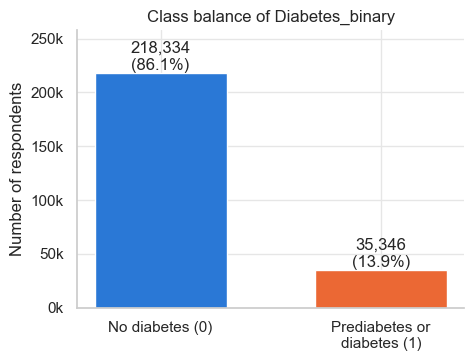

{0: 218334, 1: 35346} {0: 86.1, 1: 13.9}


In [5]:
counts = df[TARGET].value_counts().sort_index()
pct = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(5, 3.6))
bars = ax.bar(["No diabetes (0)", "Prediabetes or\ndiabetes (1)"], counts.values,
              color=[MAIN_COLOR, ACCENT_COLOR], width=0.6)
for bar, c, p in zip(bars, counts.values, pct.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{c:,}\n({p:.1f}%)",
            ha="center", va="bottom")
ax.set_ylim(0, counts.max() * 1.18)
ax.set_ylabel("Number of respondents")
ax.set_title("Class balance of Diabetes_binary")
ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v/1000:.0f}k"))
show(fig, "eda_class_balance.png")
print(counts.to_dict(), pct.round(1).to_dict())

**Observation.** 218,334 respondents (86.1%) have no diabetes and 35,346 (13.9%) have prediabetes
or diabetes. A model that always predicts 0 is already 86.1% accurate, so accuracy cannot separate
a useful model from a useless one here. I use recall, F1, ROC-AUC, and PR-AUC instead.

### 2.3 Numeric features

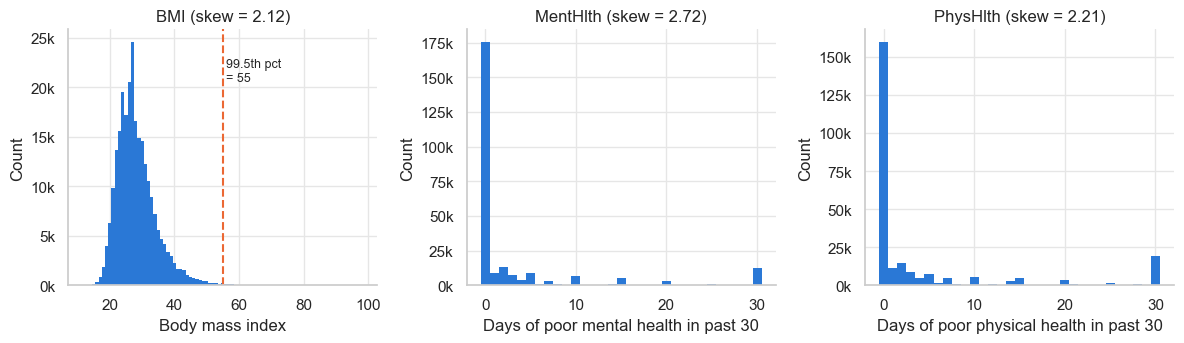

,skew,median,mean,max,pct_zero,pct_30
BMI,2.12,27.0,28.38,98,0.00,5.74
MentHlth,2.72,0.0,3.18,30,69.25,4.77
PhysHlth,2.21,0.0,4.24,30,63.09,7.65


BMI rows above 60: 805


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, col in zip(axes, NUMERIC):
    bins = np.arange(df[col].min(), df[col].max() + 2) - 0.5
    ax.hist(df[col], bins=bins, color=MAIN_COLOR, edgecolor="none")
    ax.set_title(f"{col} (skew = {df[col].skew():.2f})")
    ax.set_xlabel(DESCRIPTIONS[col])
    ax.set_ylabel("Count")
    ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v/1000:.0f}k"))
p995 = df["BMI"].quantile(0.995)
axes[0].axvline(p995, color=ACCENT_COLOR, ls="--", lw=1.5)
axes[0].text(p995 + 1, axes[0].get_ylim()[1] * 0.8, f"99.5th pct\n= {p995:.0f}", fontsize=9)
fig.tight_layout()
show(fig, "eda_numeric_hist.png")

num_stats = pd.DataFrame({
    "skew": df[NUMERIC].skew(), "median": df[NUMERIC].median(), "mean": df[NUMERIC].mean(),
    "max": df[NUMERIC].max(), "pct_zero": (df[NUMERIC] == 0).mean() * 100,
    "pct_30": (df[NUMERIC] == 30).mean() * 100,
}).round(2)
display(num_stats)
print("BMI rows above 60:", int((df["BMI"] > 60).sum()))

**Observation.** All three numeric features are right skewed. BMI has skew 2.12 (median 27, mean
28.4) and a long tail up to 98, with 805 rows above 60. MentHlth and PhysHlth are counts of days,
mostly 0 (69.3% and 63.1% of rows) with a second bump at 30 (4.8% and 7.6%). They are not bell
shaped, which matters for Gaussian Naive Bayes. The BMI tail matters for KNN distances, so BMI is
clipped in preprocessing.

### 2.4 Diabetes rate by age, general health, and income

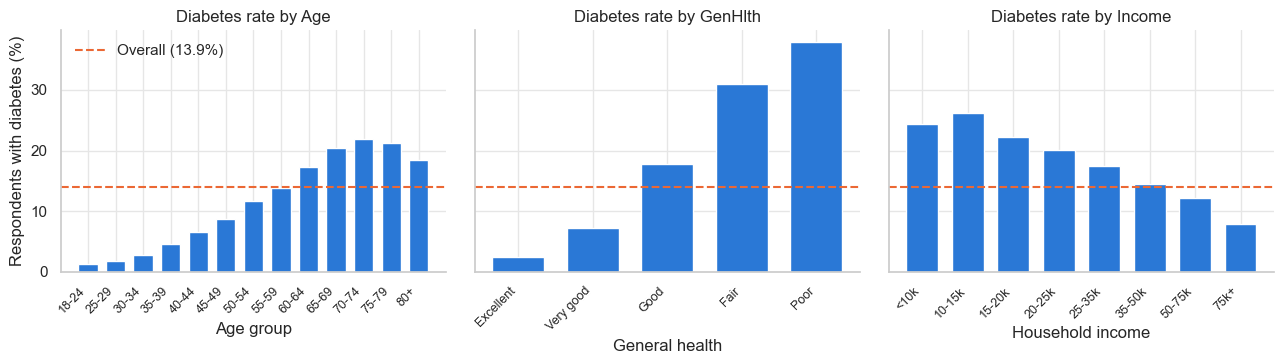

Age {1: 1.4, 2: 1.8, 3: 2.8, 4: 4.5, 5: 6.5, 6: 8.8, 7: 11.7, 8: 13.8, 9: 17.2, 10: 20.4, 11: 21.8, 12: 21.3, 13: 18.5}
GenHlth {1: 2.5, 2: 7.2, 3: 17.8, 4: 31.0, 5: 37.9}
Income {1: 24.3, 2: 26.2, 3: 22.3, 4: 20.1, 5: 17.4, 6: 14.5, 7: 12.2, 8: 8.0}


In [7]:
AGE_LABELS = ["18-24", "25-29", "30-34", "35-39", "40-44", "45-49", "50-54",
              "55-59", "60-64", "65-69", "70-74", "75-79", "80+"]
GENHLTH_LABELS = ["Excellent", "Very good", "Good", "Fair", "Poor"]
INCOME_LABELS = ["<10k", "10-15k", "15-20k", "20-25k", "25-35k", "35-50k", "50-75k", "75k+"]
overall = df[TARGET].mean() * 100

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
rates = {}
for ax, (col, labels, xlabel) in zip(axes, [("Age", AGE_LABELS, "Age group"),
                                            ("GenHlth", GENHLTH_LABELS, "General health"),
                                            ("Income", INCOME_LABELS, "Household income")]):
    r = df.groupby(col)[TARGET].mean() * 100
    rates[col] = r.round(1)
    ax.bar(range(len(r)), r.values, color=MAIN_COLOR, width=0.7)
    ax.axhline(overall, color=ACCENT_COLOR, ls="--", lw=1.5, label=f"Overall ({overall:.1f}%)")
    ax.set_xticks(range(len(r)))
    ax.set_xticklabels(labels, rotation=45, ha="right", fontsize=9)
    ax.set_xlabel(xlabel)
    ax.set_title(f"Diabetes rate by {col}")
axes[0].set_ylabel("Respondents with diabetes (%)")
axes[0].legend(loc="upper left", frameon=False)
fig.tight_layout()
show(fig, "eda_rate_by_ordinal.png")
for col, r in rates.items():
    print(col, r.to_dict())

**Observation.** The diabetes rate rises steadily with age, from 1.4% (18-24) to 21.8% (70-74),
then falls to 18.5% for 80+, possibly a survivor effect. Self-rated general health has the
sharpest gradient, from 2.5% for "excellent" to 37.9% for "poor". Income runs the other way, from
24.3% in the lowest bracket to 8.0% in the highest. These relationships are close to monotonic,
which suits a linear model.

### 2.5 Binary features

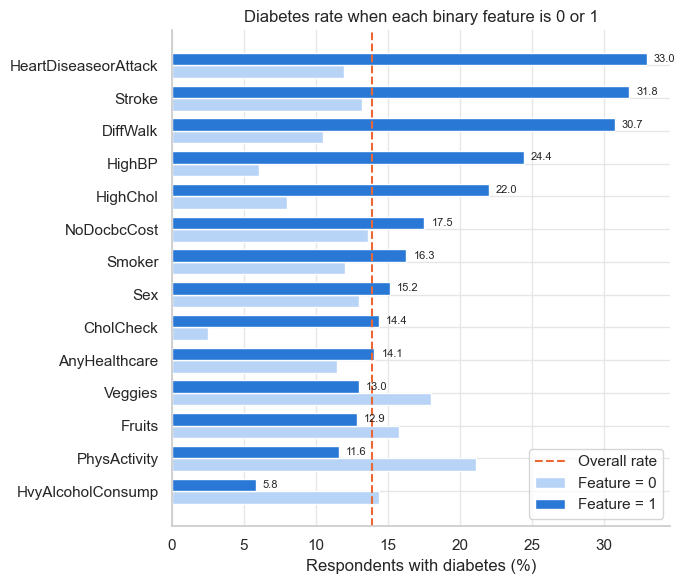

,rate_0,rate_1
feature,,
HeartDiseaseorAttack,12.0,33.0
Stroke,13.2,31.8
DiffWalk,10.5,30.7
HighBP,6.0,24.4
HighChol,8.0,22.0
NoDocbcCost,13.6,17.5
Smoker,12.1,16.3
Sex,13.0,15.2
CholCheck,2.5,14.4


Mean Age code by HvyAlcoholConsump: {0: 8.1, 1: 7.6}


In [8]:
rows = []
for col in BINARY:
    g = df.groupby(col)[TARGET].mean() * 100
    rows.append({"feature": col, "rate_0": g[0], "rate_1": g[1]})
binr = pd.DataFrame(rows).sort_values("rate_1")

y = np.arange(len(binr))
h = 0.38
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(y - h / 2, binr["rate_0"], height=h, color="#b7d3f6", label="Feature = 0")
ax.barh(y + h / 2, binr["rate_1"], height=h, color=MAIN_COLOR, label="Feature = 1")
for yi, v in zip(y, binr["rate_1"]):
    ax.text(v + 0.5, yi + h / 2, f"{v:.1f}", va="center", fontsize=8)
ax.axvline(overall, color=ACCENT_COLOR, ls="--", lw=1.5, label="Overall rate")
ax.set_yticks(y)
ax.set_yticklabels(binr["feature"])
ax.set_xlabel("Respondents with diabetes (%)")
ax.set_title("Diabetes rate when each binary feature is 0 or 1")
ax.legend(loc="lower right")
fig.tight_layout()
show(fig, "eda_binary_rates.png")

display(binr.set_index("feature").round(1).iloc[::-1])
print("Mean Age code by HvyAlcoholConsump:",
      df.groupby("HvyAlcoholConsump")["Age"].mean().round(1).to_dict())

**Observation.** The largest differences are for heart disease (33.0% vs 12.0%), stroke (31.8% vs
13.2%), difficulty walking (30.7% vs 10.5%), and high blood pressure (24.4% vs 6.0%). Physical
activity, fruit, vegetables, and heavy alcohol use point the other way. The alcohol result
(5.8% vs 14.4%) is surprising. Heavy drinkers are slightly younger (mean age code 7.6 vs 8.1),
and people with diabetes may be told to cut back, so this is an association, not a cause.

### 2.6 Correlations

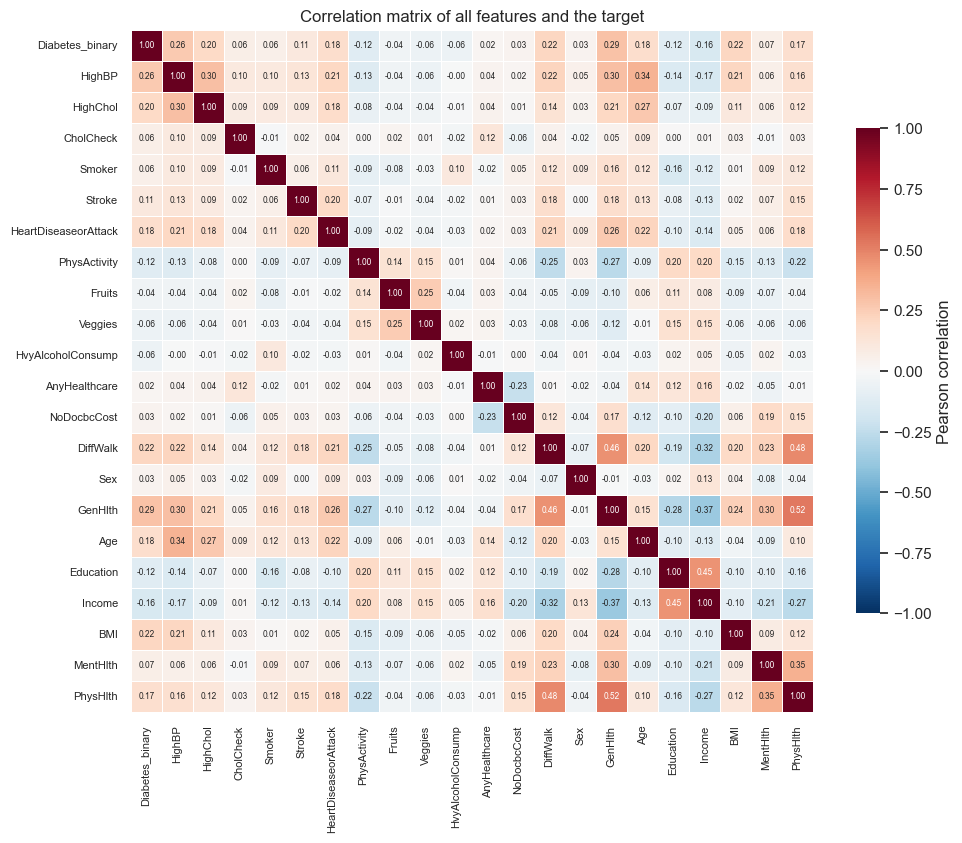

Correlation with target (top 5): {'GenHlth': 0.294, 'HighBP': 0.263, 'DiffWalk': 0.218, 'BMI': 0.217, 'HighChol': 0.2}
|r| < 0.05 with target: ['Fruits', 'NoDocbcCost', 'Sex', 'AnyHealthcare']
Most correlated feature pairs: {('GenHlth', 'PhysHlth'): 0.524, ('DiffWalk', 'PhysHlth'): 0.478, ('DiffWalk', 'GenHlth'): 0.457, ('Education', 'Income'): 0.449}


In [9]:
corr = df[[TARGET] + FEATURES].corr()
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, cmap="RdBu_r", vmin=-1, vmax=1, center=0, square=True, annot=True,
            fmt=".2f", annot_kws={"size": 6}, linewidths=0.4, linecolor="white",
            cbar_kws={"shrink": 0.7, "label": "Pearson correlation"}, ax=ax)
ax.set_title("Correlation matrix of all features and the target")
ax.tick_params(labelsize=8)
show(fig, "eda_corr_heatmap.png")

with_target = corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)
print("Correlation with target (top 5):", with_target.head(5).round(3).to_dict())
print("|r| < 0.05 with target:", list(with_target[with_target.abs() < 0.05].index))
mask = np.triu(np.ones((len(FEATURES),) * 2), k=1) == 1
pairs = corr.loc[FEATURES, FEATURES].where(mask).stack().sort_values(key=abs, ascending=False)
print("Most correlated feature pairs:", pairs.head(4).round(3).to_dict())

**Observation.** The features most correlated with the target are GenHlth (+0.294), HighBP
(+0.263), DiffWalk (+0.218), BMI (+0.217), and HighChol (+0.200). Fruits, NoDocbcCost, Sex, and
AnyHealthcare are below 0.05 in absolute value. Several features are correlated with each other,
most strongly GenHlth and PhysHlth (+0.524), DiffWalk and PhysHlth (+0.478), DiffWalk and GenHlth
(+0.457), and Education and Income (+0.449). These pairs carry overlapping information, which
breaks the independence assumption of Naive Bayes.

## 3. Cleaning and preprocessing

Every step below is explained, including the ones where nothing needed to change.

- **Missing values.** None (checked in Section 1), so no imputation.
- **Types.** Cast from float to int after checking every value is whole (Section 1).
- **Duplicates.** Removed (next cell), because a duplicate row can land in both train and test.
- **Encoding.** Not needed. Binary features stay 0/1. The ordinal codes (GenHlth, Age, Education,
  Income) keep their order as single integers. One-hot encoding would throw the order away and
  turn these 4 columns into 32.
- **Outliers.** BMI is clipped at the 99.5th percentile of the training set instead of deleting
  rows, because extreme BMI values are rare but possible.
- **Scaling.** `StandardScaler` for Logistic Regression and KNN. Gaussian Naive Bayes fits its
  own mean and variance per feature, so scaling does not change it.
- **Split.** Stratified 70/15/15 train/validation/test.
- **Class imbalance.** `class_weight` is tuned for Logistic Regression, and the decision
  threshold is tuned on the validation set for every model.

### 3.1 Duplicates

In [10]:
dup_mask = df.duplicated()
print("Exact duplicate rows:", int(dup_mask.sum()))
print("Positive rate among the duplicates: {:.1%}".format(df.loc[dup_mask, TARGET].mean()))
print("Positive rate before: {:.1%}".format(df[TARGET].mean()))

data = df.drop_duplicates().reset_index(drop=True)
print("Rows after removal:", len(data))
print("Positive rate after: {:.1%}".format(data[TARGET].mean()))

Exact duplicate rows: 24206
Positive rate among the duplicates: 1.0%
Positive rate before: 13.9%
Rows after removal: 229474
Positive rate after: 15.3%


**Why remove them.** 24,206 rows are exact copies of another row. They may be different people
who gave the same coarse answers, but a duplicate can land in both the training and test sets, so
the model would be scored on rows it has already seen. Only 1.0% of the removed rows are positive,
so the positive rate rises from 13.9% to 15.3%. Experiment E4 (Section 8) measures the effect.

### 3.2 Train / validation / test split

Stratified on the target so each set keeps the same 15.3% positive rate. The validation set is
used to tune KNN's `k` and the decision thresholds. The test set is touched once, in Section 6.

In [11]:
def split(frame):
    # Stratified 70/15/15 split. VAL_SIZE is a fraction of the whole dataset, so it is
    # rescaled for the 85% left after the test split.
    X, y = frame[FEATURES], frame[TARGET]
    X_rest, X_test, y_rest, y_test = train_test_split(
        X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)
    X_train, X_val, y_train, y_val = train_test_split(
        X_rest, y_rest, test_size=VAL_SIZE / (1 - TEST_SIZE), stratify=y_rest,
        random_state=RANDOM_STATE)
    return X_train, X_val, X_test, y_train, y_val, y_test


X_train, X_val, X_test, y_train, y_val, y_test = split(data)
display(pd.DataFrame({
    "rows": [len(y_train), len(y_val), len(y_test)],
    "positives": [int(y_train.sum()), int(y_val.sum()), int(y_test.sum())],
    "positive_rate": [round(y_train.mean(), 4), round(y_val.mean(), 4), round(y_test.mean(), 4)],
}, index=["train", "validation", "test"]))

,rows,positives,positive_rate
train,160631,24568,0.1529
validation,34421,5264,0.1529
test,34422,5265,0.1530


### 3.3 Outlier clipping and scaling inside a pipeline

All steps that learn from data live inside an sklearn `Pipeline` and `ColumnTransformer`, so they
are fit on training rows only (including inside each cross-validation fold) and applied unchanged
to validation and test rows.

`ClipUpper` learns the 99.5th percentile of BMI from the data passed to `fit`.

**Why scale.** KNN uses Euclidean distance. Without scaling, BMI (range 12 to 56 after clipping)
outweighs every 0/1 feature. Logistic Regression's gradient-based solver and L2 penalty also work
better when features share a scale, because the penalty then treats every weight equally.

In [12]:
class ClipUpper(BaseEstimator, TransformerMixin):
    # Clip values above a percentile learned from the training data passed to fit.

    def __init__(self, percentile=BMI_CLIP_PERCENTILE):
        self.percentile = percentile

    def fit(self, X, y=None):
        self.upper_ = np.percentile(np.asarray(X, dtype=float), self.percentile, axis=0)
        return self

    def transform(self, X):
        return np.minimum(np.asarray(X, dtype=float), self.upper_)

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)


def build_preprocessor(scale=True, features=FEATURES):
    # Clip BMI, then standardize every feature if scale=True (LR and KNN).
    # Gaussian NB uses scale=False. `features` lets experiment E3 use a subset of columns.
    features = list(features)
    others = [f for f in features if f != "BMI"]
    bmi_steps = [("clip", ClipUpper())]
    if scale:
        bmi_steps.append(("scale", StandardScaler()))
    parts = [("other", StandardScaler() if scale else "passthrough", others)]
    if "BMI" in features:
        parts.insert(0, ("bmi", Pipeline(bmi_steps), ["BMI"]))
    return ColumnTransformer(parts, verbose_feature_names_out=False)


clip = ClipUpper().fit(X_train[["BMI"]])
print("BMI cutoff learned from train:", clip.upper_[0])
print("Training rows clipped:", int((X_train["BMI"] > clip.upper_[0]).sum()))

check = build_preprocessor(scale=True).fit(X_train).transform(X_train)
print("After scaling, largest absolute feature mean:", round(float(np.abs(check.mean(0)).max()), 6),
      "| standard deviations from", round(float(check.std(0).min()), 3),
      "to", round(float(check.std(0).max()), 3))

BMI cutoff learned from train: 56.0
Training rows clipped: 747
After scaling, largest absolute feature mean: 0.0 | standard deviations from 1.0 to 1.0


## 4. Models

The three models come from three different families covered in the course, so comparing them
tests which assumptions fit this data.

| Model | Family | How it predicts | Tuned hyperparameters |
|---|---|---|---|
| Majority baseline | none | Always predicts "no diabetes" | none |
| Logistic Regression | discriminative, linear | $\hat{y}=\sigma(\mathbf{w}^\top\mathbf{x}+b)$, trained on log loss with an L2 penalty | `C`, `class_weight` |
| Gaussian Naive Bayes | generative | $P(y\mid\mathbf{x}) \propto P(y)\prod_j P(x_j\mid y)$ with a normal $P(x_j\mid y)$ | `var_smoothing` |
| K-Nearest Neighbors | non-parametric | Fraction of positive cases among the $k$ nearest training points (Euclidean) | `k`, `weights` |

**Expectations.** Logistic Regression should do well because the strongest features relate to
risk almost monotonically (Section 2.4). Naive Bayes should trail, because features are correlated
(Section 2.6) and mostly binary, not Gaussian. KNN makes no linearity assumption but should need a
large `k`, since many points share the same coarse answers. It is also slow to predict.

In [13]:
def make_baseline():
    # Always predicts the majority class. predict_proba returns the training positive rate.
    return DummyClassifier(strategy="prior")


def make_lr(features=FEATURES, **params):
    # L2 penalty is the default. lbfgs is a gradient-based solver.
    clf = LogisticRegression(max_iter=2000, random_state=RANDOM_STATE, **params)
    return Pipeline([("prep", build_preprocessor(True, features)), ("clf", clf)])


def make_nb(**params):
    return Pipeline([("prep", build_preprocessor(False)), ("clf", GaussianNB(**params))])


def make_knn(scale=True, **params):
    clf = KNeighborsClassifier(n_jobs=-1, **params)
    return Pipeline([("prep", build_preprocessor(scale)), ("clf", clf)])


LR_GRID = {"clf__C": [0.001, 0.01, 0.1, 1, 10], "clf__class_weight": [None, "balanced"]}
NB_GRID = {"clf__var_smoothing": [1e-9, 1e-7, 1e-5, 1e-3]}
KNN_GRID = {"n_neighbors": [5, 15, 31, 51, 101, 201], "weights": ["uniform", "distance"]}
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

## 5. Training and tuning

- **Logistic Regression and Naive Bayes:** `GridSearchCV` with 5-fold stratified CV on the
  training set, scored by ROC-AUC. The best setting is refit on the full training set.
- **KNN:** CV on 160k rows is slow, so each `(k, weights)` pair is fit on a stratified 40,000-row
  subsample of train and scored by ROC-AUC on the validation set. The best setting is refit on the
  full training set. For a mean and standard deviation comparable to the other models, I also run
  5-fold CV of that setting on the subsample.

### 5.1 Baseline and Logistic Regression

In [14]:
fitted, cv_rows = {}, []

t0 = time.perf_counter()
fitted["Baseline"] = make_baseline().fit(X_train, y_train)
base_fit = time.perf_counter() - t0
base_cv = cross_val_score(make_baseline(), X_train, y_train, scoring="roc_auc", cv=CV)
cv_rows.append({"model": "Baseline", "best_params": "strategy=prior",
                "cv_auc_mean": base_cv.mean(), "cv_auc_std": base_cv.std(),
                "tune_time_s": 0.0, "fit_time_s": base_fit})


def grid_search(pipe, grid):
    search = GridSearchCV(pipe, grid, scoring="roc_auc", cv=CV, n_jobs=-1, refit=True)
    t0 = time.perf_counter()
    search.fit(X_train, y_train)
    tune_s = time.perf_counter() - t0
    i = search.best_index_
    params = {k.replace("clf__", ""): v for k, v in search.best_params_.items()}
    row = {"best_params": str(params), "cv_auc_mean": search.cv_results_["mean_test_score"][i],
           "cv_auc_std": search.cv_results_["std_test_score"][i],
           "tune_time_s": tune_s, "fit_time_s": search.refit_time_}
    return search, params, row


lr_search, lr_params, row = grid_search(make_lr(), LR_GRID)
fitted["Logistic Regression"] = lr_search.best_estimator_
cv_rows.append({"model": "Logistic Regression", **row})
print("Best LR params:", lr_params)
display(pd.DataFrame(lr_search.cv_results_)[
    ["param_clf__C", "param_clf__class_weight", "mean_test_score", "std_test_score"]].round(4))

Best LR params: {'C': 0.001, 'class_weight': 'balanced'}


,param_clf__C,param_clf__class_weight,mean_test_score,std_test_score
0,0.001,None,0.8068,0.0024
1,0.001,balanced,0.8069,0.0024
2,0.010,None,0.8068,0.0024
3,0.010,balanced,0.8069,0.0024
4,0.100,None,0.8068,0.0024
5,0.100,balanced,0.8069,0.0024
6,1.000,None,0.8068,0.0024
7,1.000,balanced,0.8069,0.0024
8,10.000,None,0.8068,0.0024
9,10.000,balanced,0.8069,0.0024


**Observation.** The Logistic Regression grid is flat. Every setting scores about 0.807 CV ROC-AUC,
so neither the penalty strength nor class weights change how well the model ranks people. Class
weights only shift the probabilities (see experiment E1).

### 5.2 Gaussian Naive Bayes

In [15]:
nb_search, nb_params, row = grid_search(make_nb(), NB_GRID)
fitted["Gaussian NB"] = nb_search.best_estimator_
cv_rows.append({"model": "Gaussian NB", **row})
print("Best NB params:", nb_params)
display(pd.DataFrame(nb_search.cv_results_)[
    ["param_clf__var_smoothing", "mean_test_score", "std_test_score"]].round(4))

Best NB params: {'var_smoothing': 0.001}


,param_clf__var_smoothing,mean_test_score,std_test_score
0,0.000,0.7672,0.0017
1,0.000,0.7672,0.0017
2,0.000,0.7676,0.0018
3,0.001,0.7805,0.0020


**Observation.** The largest smoothing value scores best (about 0.781 vs 0.767 for the default).
Extra variance softens Naive Bayes's overconfident probabilities. The best value sits at the edge
of the grid, so a larger value might help slightly.

### 5.3 K-Nearest Neighbors

In [16]:
X_sub, _, y_sub, _ = train_test_split(X_train, y_train, train_size=KNN_TUNE_ROWS,
                                      stratify=y_train, random_state=RANDOM_STATE)
knn_rows = []
t0 = time.perf_counter()
for k in KNN_GRID["n_neighbors"]:
    for w in KNN_GRID["weights"]:
        m = make_knn(n_neighbors=k, weights=w).fit(X_sub, y_sub)
        knn_rows.append({"n_neighbors": k, "weights": w,
                         "train_auc": roc_auc_score(y_sub, m.predict_proba(X_sub)[:, 1]),
                         "val_auc": roc_auc_score(y_val, m.predict_proba(X_val)[:, 1])})
knn_tune_s = time.perf_counter() - t0
knn_table = pd.DataFrame(knn_rows)
display(knn_table.round(4))

best = knn_table.loc[knn_table["val_auc"].idxmax()]
knn_params = {"n_neighbors": int(best["n_neighbors"]), "weights": best["weights"]}
print("Best KNN params:", knn_params)

knn_cv = cross_val_score(make_knn(**knn_params), X_sub, y_sub, scoring="roc_auc", cv=CV)
t0 = time.perf_counter()
fitted["KNN"] = make_knn(**knn_params).fit(X_train, y_train)
knn_fit = time.perf_counter() - t0
cv_rows.append({"model": "KNN", "best_params": str(knn_params), "cv_auc_mean": knn_cv.mean(),
                "cv_auc_std": knn_cv.std(), "tune_time_s": knn_tune_s, "fit_time_s": knn_fit})

,n_neighbors,weights,train_auc,val_auc
0,5,uniform,0.8940,0.7052
1,5,distance,1.0000,0.7049
2,15,uniform,0.8422,0.7644
3,15,distance,1.0000,0.7619
4,31,uniform,0.8237,0.7855
5,31,distance,1.0000,0.7816
6,51,uniform,0.8150,0.7924
7,51,distance,1.0000,0.7883
8,101,uniform,0.8062,0.7969
9,101,distance,1.0000,0.7926


Best KNN params: {'n_neighbors': 201, 'weights': 'uniform'}


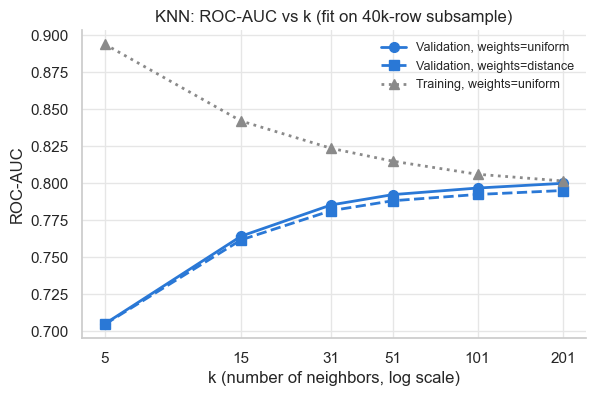

In [17]:
fig, ax = plt.subplots(figsize=(6.5, 4))
for w, ls, marker in [("uniform", "-", "o"), ("distance", "--", "s")]:
    t = knn_table[knn_table["weights"] == w]
    ax.plot(t["n_neighbors"], t["val_auc"], ls=ls, marker=marker, color=MAIN_COLOR, lw=2, ms=7,
            label=f"Validation, weights={w}")
t = knn_table[knn_table["weights"] == "uniform"]
ax.plot(t["n_neighbors"], t["train_auc"], ls=":", marker="^", color="#8a8a8a", lw=2, ms=7,
        label="Training, weights=uniform")
ax.set_xscale("log")
ax.set_xticks(KNN_GRID["n_neighbors"])
ax.set_xticklabels(KNN_GRID["n_neighbors"])
ax.set_xlabel("k (number of neighbors, log scale)")
ax.set_ylabel("ROC-AUC")
ax.set_title("KNN: ROC-AUC vs k (fit on 40k-row subsample)")
ax.legend(frameon=False, fontsize=9)
show(fig, "knn_k_curve.png")

**Observation (bias/variance).** At `k = 5` the training ROC-AUC is 0.894 but validation is only
0.705, a clear sign of overfitting (high variance). As `k` grows the two curves meet, at 0.802 and
0.800 for `k = 201`. Validation ROC-AUC is still rising slowly at the end of the grid. Distance
weighting is worse than uniform weighting at every `k`, and its training score is about 1.0
because each training point is its own nearest neighbor.

### 5.4 Tuning summary

In [18]:
cv_results = pd.DataFrame(cv_rows).set_index("model")
display(cv_results.round(4))

,best_params,cv_auc_mean,cv_auc_std,tune_time_s,fit_time_s
model,,,,,
Baseline,strategy=prior,0.5000,0.0000,0.0000,0.0150
Logistic Regression,"{'C': 0.001, 'class_weight': 'balanced'}",0.8069,0.0024,4.8297,0.1431
Gaussian NB,{'var_smoothing': 0.001},0.7805,0.0020,0.7400,0.0615
KNN,"{'n_neighbors': 201, 'weights': 'uniform'}",0.7933,0.0053,24.2357,0.1105


### 5.5 Decision threshold tuning on the validation set

Each model outputs a probability. Instead of the default 0.5, I pick the threshold that maximizes
F1 on the validation set. A row is predicted positive when its probability is at or above the
threshold. This handles the class imbalance for all models, including Naive Bayes and KNN, which
have no class weights.

In [19]:
def best_f1_threshold(y_true, proba):
    # Return the probability cutoff that maximizes F1, and that F1.
    precision, recall, thresholds = precision_recall_curve(y_true, proba)
    p, r = precision[:-1], recall[:-1]   # the last pair has no threshold
    f1 = np.divide(2 * p * r, p + r, out=np.zeros_like(p), where=(p + r) > 0)
    i = int(np.argmax(f1))
    return float(thresholds[i]), float(f1[i])


thresholds, th_rows = {}, []
for name, model in fitted.items():
    proba = model.predict_proba(X_val)[:, 1]
    thresholds[name], f1 = best_f1_threshold(y_val, proba)
    th_rows.append({"model": name, "threshold": thresholds[name], "val_f1": f1,
                    "val_auc": roc_auc_score(y_val, proba)})
display(pd.DataFrame(th_rows).set_index("model").round(4))

,threshold,val_f1,val_auc
model,,,
Baseline,0.1529,0.2653,0.5000
Logistic Regression,0.6435,0.4651,0.8111
Gaussian NB,0.1565,0.4353,0.7872
KNN,0.2388,0.4618,0.8058


## 6. Test set evaluation

Every hyperparameter and threshold is now fixed. The test set is scored once, for every model, at
the default 0.5 threshold and at the validation-tuned threshold.

In [20]:
def metrics_at(y_true, proba, threshold):
    pred = (proba >= threshold).astype(int)
    return {"accuracy": accuracy_score(y_true, pred),
            "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred), "f1": f1_score(y_true, pred),
            "roc_auc": roc_auc_score(y_true, proba),
            "pr_auc": average_precision_score(y_true, proba)}


rows, probas = [], {}
for name, model in fitted.items():
    t0 = time.perf_counter()
    probas[name] = model.predict_proba(X_test)[:, 1]
    pred_s = time.perf_counter() - t0
    for label, th in [("default", 0.5), ("tuned", thresholds[name])]:
        rows.append({"model": name, "threshold_type": label, "threshold": th,
                     **metrics_at(y_test, probas[name], th), "predict_time_s": pred_s})
test_metrics = pd.DataFrame(rows)
display(test_metrics.round(4))

,model,threshold_type,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc,predict_time_s
0,Baseline,default,0.5000,0.8470,0.0000,0.0000,0.0000,0.5000,0.1530,0.0006
1,Baseline,tuned,0.1529,0.1530,0.1530,1.0000,0.2653,0.5000,0.1530,0.0006
2,Logistic Regression,default,0.5000,0.7169,0.3213,0.7647,0.4524,0.8140,0.4303,0.0070
3,Logistic Regression,tuned,0.6435,0.8000,0.3943,0.5740,0.4675,0.8140,0.4303,0.0070
4,Gaussian NB,default,0.5000,0.7968,0.3678,0.4570,0.4076,0.7871,0.3734,0.0166
5,Gaussian NB,tuned,0.1565,0.7395,0.3262,0.6598,0.4366,0.7871,0.3734,0.0166
6,KNN,default,0.5000,0.8515,0.6659,0.0579,0.1066,0.8059,0.4175,3.6151
7,KNN,tuned,0.2388,0.7831,0.3720,0.6074,0.4614,0.8059,0.4175,3.6151


**Observation.** Logistic Regression has the best ROC-AUC (0.814) and PR-AUC (0.430). KNN is about
0.008 behind on ROC-AUC and Naive Bayes about 0.027 behind. The order matches cross-validation and
validation, so it is not the result of one lucky split.

Accuracy is misleading. The baseline reaches 0.847 accuracy without finding a single positive
case, and KNN at 0.5 has the highest accuracy of all (0.8515) while finding only 5.8% of positives.
Tuning the threshold raises KNN's recall from 0.058 to 0.607. KNN is also hundreds of times slower
to predict than Logistic Regression (see `predict_time_s`), because it compares every test row with
all 160,631 training rows.

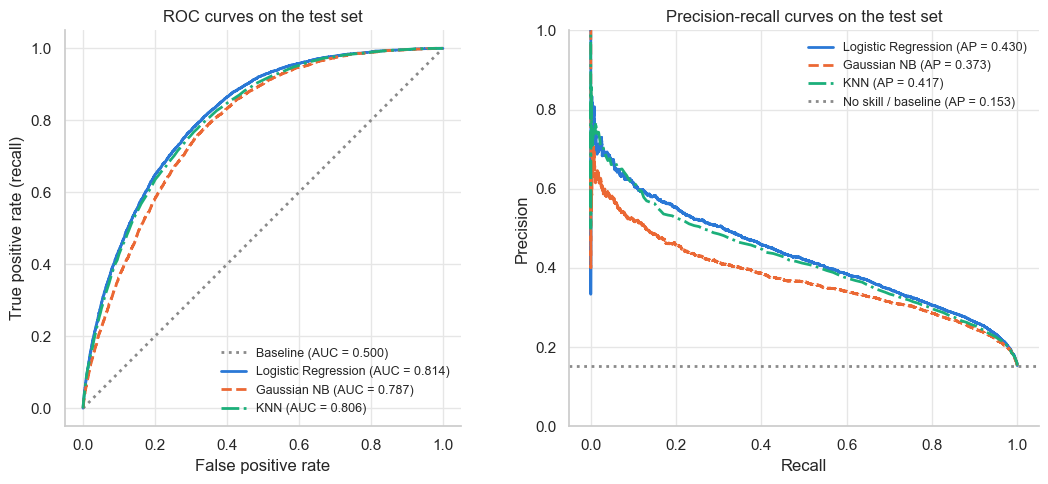

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
ax = axes[0]
for name, proba in probas.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    ax.plot(fpr, tpr, color=MODEL_COLORS[name], ls=MODEL_STYLES[name], lw=2,
            label=f"{name} (AUC = {roc_auc_score(y_test, proba):.3f})")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate (recall)")
ax.set_title("ROC curves on the test set")
ax.legend(loc="lower right", frameon=False, fontsize=9)
ax.set_aspect("equal")

ax = axes[1]
for name, proba in probas.items():
    if name == "Baseline":
        continue
    p, r, _ = precision_recall_curve(y_test, proba)
    ax.plot(r, p, color=MODEL_COLORS[name], ls=MODEL_STYLES[name], lw=2,
            label=f"{name} (AP = {average_precision_score(y_test, proba):.3f})")
ax.axhline(y_test.mean(), color=MODEL_COLORS["Baseline"], ls=":", lw=2,
           label=f"No skill / baseline (AP = {y_test.mean():.3f})")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_ylim(0, 1)
ax.set_title("Precision-recall curves on the test set")
ax.legend(loc="upper right", frameon=False, fontsize=9)
fig.tight_layout()
if SAVE_FIGURES:
    # Save each panel on its own for the report.
    for i, name in enumerate(["roc_curves.png", "pr_curves.png"]):
        FIG_DIR.mkdir(exist_ok=True)
        extent = axes[i].get_tightbbox(fig.canvas.get_renderer()).transformed(
            fig.dpi_scale_trans.inverted())
        fig.savefig(FIG_DIR / name, dpi=200, bbox_inches=extent.expanded(1.02, 1.02))
plt.show()

**Observation.** The Logistic Regression and KNN curves nearly overlap. The Naive Bayes
precision-recall curve is lower at most recall levels. Every model is far above the no-skill line
at the test positive rate (0.153).

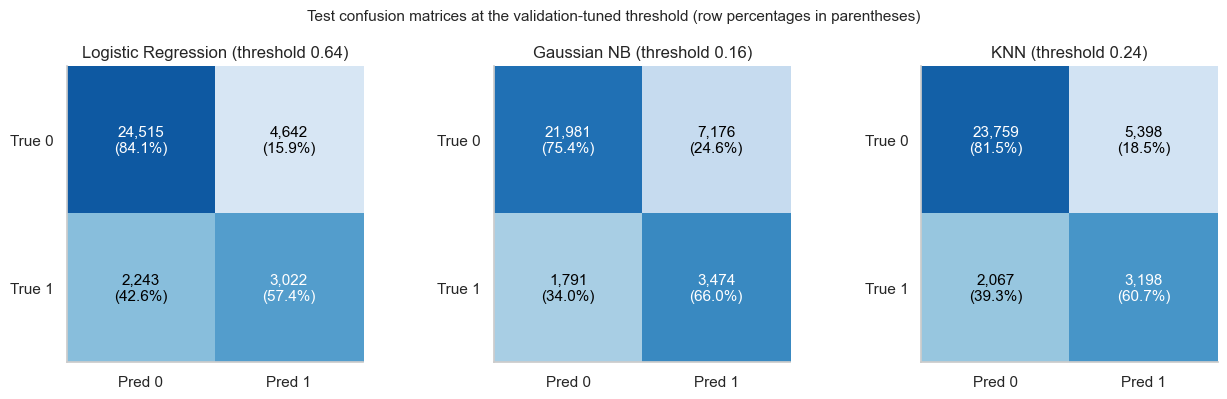

,tn,fp,fn,tp,pct_negatives_flagged,pct_positives_found
model,,,,,,
Logistic Regression,24515,4642,2243,3022,15.9,57.4
Gaussian NB,21981,7176,1791,3474,24.6,66.0
KNN,23759,5398,2067,3198,18.5,60.7


In [22]:
names = ["Logistic Regression", "Gaussian NB", "KNN"]
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
cm_rows = []
for ax, name in zip(axes, names):
    th = thresholds[name]
    cm = confusion_matrix(y_test, (probas[name] >= th).astype(int))
    row_pct = cm / cm.sum(axis=1, keepdims=True) * 100
    (tn, fp), (fn, tp) = cm
    cm_rows.append({"model": name, "tn": tn, "fp": fp, "fn": fn, "tp": tp,
                    "pct_negatives_flagged": row_pct[0, 1], "pct_positives_found": row_pct[1, 1]})
    ax.imshow(row_pct, cmap="Blues", vmin=0, vmax=100)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}\n({row_pct[i, j]:.1f}%)", ha="center", va="center",
                    fontsize=11, color="white" if row_pct[i, j] > 55 else "black")
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Pred 0", "Pred 1"])
    ax.set_yticks([0, 1])
    ax.set_yticklabels(["True 0", "True 1"])
    ax.set_title(f"{name} (threshold {th:.2f})")
    ax.grid(False)
fig.suptitle("Test confusion matrices at the validation-tuned threshold "
             "(row percentages in parentheses)", fontsize=11)
fig.tight_layout()
show(fig, "confusion_matrices.png")
display(pd.DataFrame(cm_rows).set_index("model").round(1))

**Observation.** Of the 5,265 positive test cases, Logistic Regression finds 3,022 (57.4%) and
wrongly flags 4,642 of 29,157 negatives (15.9%). Naive Bayes finds more positives (66.0%) but flags
many more negatives (24.6%). KNN sits between them (60.7% found, 18.5% flagged).

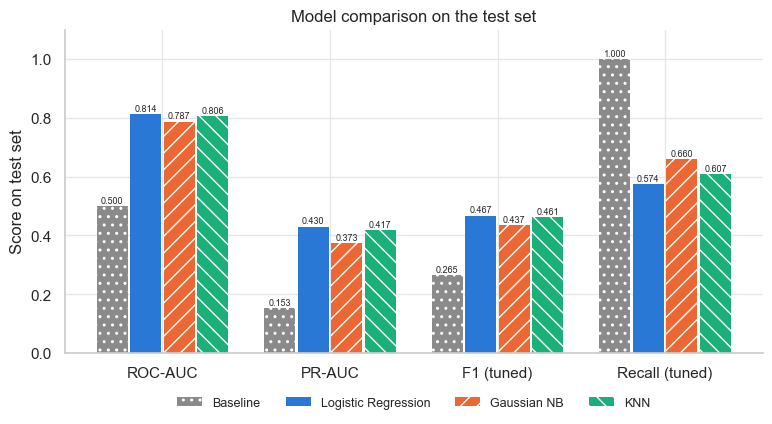

In [23]:
tuned = test_metrics[test_metrics["threshold_type"] == "tuned"].set_index("model")
metrics = [("roc_auc", "ROC-AUC"), ("pr_auc", "PR-AUC"), ("f1", "F1 (tuned)"),
           ("recall", "Recall (tuned)")]
x = np.arange(len(metrics))
w = 0.8 / len(tuned)
fig, ax = plt.subplots(figsize=(9, 4.2))
for i, name in enumerate(tuned.index):
    vals = [tuned.loc[name, m] for m, _ in metrics]
    bars = ax.bar(x + (i - (len(tuned) - 1) / 2) * w, vals, width=w * 0.92,
                  color=MODEL_COLORS[name], label=name, edgecolor="white", linewidth=0,
                  hatch={"Baseline": "..", "Gaussian NB": "//", "KNN": "\\\\"}.get(name, ""))
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.3f}", ha="center", fontsize=6.5)
ax.set_xticks(x)
ax.set_xticklabels([lab for _, lab in metrics])
ax.set_ylim(0, 1.1)
ax.set_ylabel("Score on test set")
ax.set_title("Model comparison on the test set")
ax.legend(ncol=4, loc="upper center", frameon=False, fontsize=9, bbox_to_anchor=(0.5, -0.1))
show(fig, "model_comparison.png")

## 7. Interpretation

### 7.1 Logistic Regression coefficients

The features are standardized, so each coefficient is the change in log-odds for a one standard
deviation change in that feature. I also refit with a weak penalty (`C = 1`) to check that the
strong penalty chosen by CV (`C = 0.001`) is not what makes some weights small.

,coefficient,coefficient_C1
GenHlth,0.543,0.575
BMI,0.461,0.482
Age,0.427,0.454
HighBP,0.343,0.346
HighChol,0.270,0.276
CholCheck,0.231,0.253
HvyAlcoholConsump,-0.175,-0.183
Sex,0.137,0.144
Income,-0.101,-0.102
HeartDiseaseorAttack,0.075,0.070


Largest change between C=0.001 and C=1: 0.032


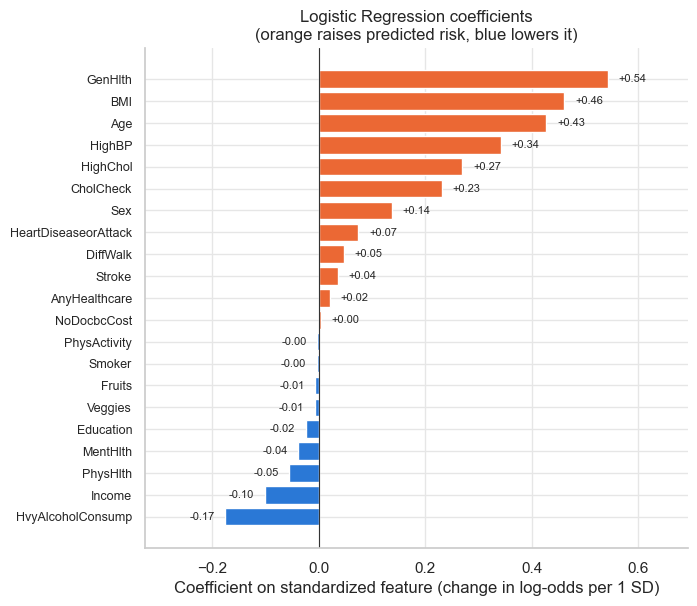

In [24]:
lr_model = fitted["Logistic Regression"]
coef_names = lr_model.named_steps["prep"].get_feature_names_out()
weak = make_lr(**{**lr_params, "C": 1.0}).fit(X_train, y_train)
coef = pd.DataFrame({"coefficient": lr_model.named_steps["clf"].coef_[0],
                     "coefficient_C1": weak.named_steps["clf"].coef_[0]}, index=coef_names)
coef = coef.reindex(coef["coefficient"].abs().sort_values(ascending=False).index)
display(coef.round(3))
print("Largest change between C=0.001 and C=1:",
      round(float((coef["coefficient"] - coef["coefficient_C1"]).abs().max()), 3))

t = coef.sort_values("coefficient")
fig, ax = plt.subplots(figsize=(7, 6.5))
ax.barh(t.index, t["coefficient"],
        color=[ACCENT_COLOR if c > 0 else MAIN_COLOR for c in t["coefficient"]])
ax.axvline(0, color="#333333", lw=0.8)
for yi, c in enumerate(t["coefficient"]):
    ax.text(c + (0.02 if c >= 0 else -0.02), yi, f"{c:+.2f}", va="center",
            ha="left" if c >= 0 else "right", fontsize=8)
ax.set_xlim(t["coefficient"].min() - 0.15, t["coefficient"].max() + 0.15)
ax.set_xlabel("Coefficient on standardized feature (change in log-odds per 1 SD)")
ax.set_title("Logistic Regression coefficients\n(orange raises predicted risk, blue lowers it)")
ax.tick_params(axis="y", labelsize=9)
show(fig, "lr_coefficients.png")

**Observation.** The largest positive weights are GenHlth (+0.54), BMI (+0.46), Age (+0.43),
HighBP (+0.34), and HighChol (+0.27), which match known risk factors and the EDA. CholCheck is also
large (+0.23), likely because people who get checked are more often tested and diagnosed, so it
reflects detection rather than cause. HvyAlcoholConsump (-0.17) and Income (-0.10) lower predicted
risk, as in the raw rates. PhysActivity has a weight near zero even though its raw rates differ
(11.6% vs 21.1%), because GenHlth, BMI, and Age already carry its information. Refitting with
`C = 1` changes every weight by at most 0.032, so this is not caused by the strong penalty.

### 7.2 Learning curve (bias vs variance)

Training and cross-validated ROC-AUC for Logistic Regression as the training set grows. This uses
5-fold CV inside the training set only.

,train_size,train_auc_mean,train_auc_std,val_auc_mean,val_auc_std
0,642,0.7911,0.0177,0.7885,0.0043
1,1285,0.7929,0.0078,0.7943,0.0031
2,3855,0.8034,0.0040,0.8001,0.0025
3,12850,0.8072,0.0030,0.8048,0.0020
4,38551,0.8081,0.0015,0.8064,0.0025
5,77102,0.8084,0.0015,0.8068,0.0024
6,128504,0.8071,0.0006,0.8069,0.0024


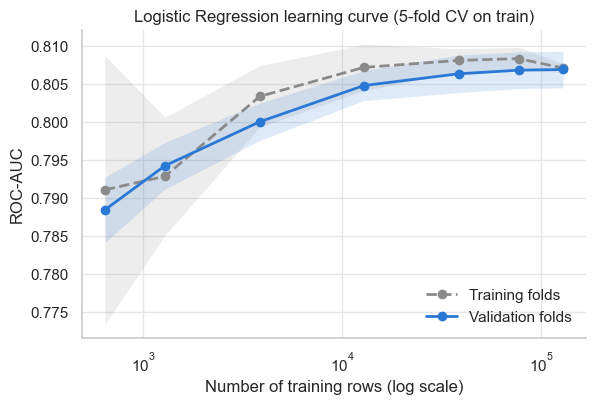

In [25]:
sizes, train_scores, val_scores = learning_curve(
    make_lr(**lr_params), X_train, y_train, cv=CV, scoring="roc_auc", n_jobs=-1,
    train_sizes=[0.005, 0.01, 0.03, 0.1, 0.3, 0.6, 1.0], shuffle=True, random_state=RANDOM_STATE)
lc = pd.DataFrame({"train_size": sizes,
                   "train_auc_mean": train_scores.mean(1), "train_auc_std": train_scores.std(1),
                   "val_auc_mean": val_scores.mean(1), "val_auc_std": val_scores.std(1)})
display(lc.round(4))

fig, ax = plt.subplots(figsize=(6.5, 4))
for col, color, ls, label in [("train", "#8a8a8a", "--", "Training folds"),
                              ("val", MAIN_COLOR, "-", "Validation folds")]:
    m, s = lc[f"{col}_auc_mean"], lc[f"{col}_auc_std"]
    ax.plot(sizes, m, color=color, ls=ls, marker="o", lw=2, ms=6, label=label)
    ax.fill_between(sizes, m - s, m + s, color=color, alpha=0.15, lw=0)
ax.set_xscale("log")
ax.set_xlabel("Number of training rows (log scale)")
ax.set_ylabel("ROC-AUC")
ax.set_title("Logistic Regression learning curve (5-fold CV on train)")
ax.legend(frameon=False)
show(fig, "lr_learning_curve.png")

**Observation.** Validation ROC-AUC rises from 0.7885 with 642 training rows to 0.806 with 38,551
and levels off at 0.807, the same as the training score at 128,504 rows. With almost no gap
between the curves, the model is limited by bias, not variance. More data of the same kind would
not help. Better features or a more flexible model would be needed.

## 8. Additional experiments

Four small experiments. No setting is chosen from these test scores, and each row picks its own
threshold on its own validation set.

- **E1:** Logistic Regression with vs without `class_weight="balanced"`
- **E2:** KNN with vs without `StandardScaler` (same `k`, same 40k subsample)
- **E3:** Logistic Regression on only the top 5 features (by absolute coefficient) vs all 21
- **E4:** Logistic Regression trained and tested with vs without duplicate removal

In [26]:
def tuned_scores(model, Xv, yv, Xt, yt):
    # Pick the F1 threshold on validation, then score test at 0.5 and at that threshold.
    th, _ = best_f1_threshold(yv, model.predict_proba(Xv)[:, 1])
    proba = model.predict_proba(Xt)[:, 1]
    d, t = metrics_at(yt, proba, 0.5), metrics_at(yt, proba, th)
    return {"threshold": th, "roc_auc": d["roc_auc"], "pr_auc": d["pr_auc"],
            "recall@0.5": d["recall"], "f1@0.5": d["f1"],
            "precision@tuned": t["precision"], "recall@tuned": t["recall"], "f1@tuned": t["f1"]}


# E1: class weights
e1 = pd.DataFrame([
    {"class_weight": str(cw),
     **tuned_scores(make_lr(**{**lr_params, "class_weight": cw}).fit(X_train, y_train),
                    X_val, y_val, X_test, y_test)}
    for cw in [None, "balanced"]])
print("E1. Logistic Regression, class weights")
display(e1.set_index("class_weight").round(4))

E1. Logistic Regression, class weights


,threshold,roc_auc,pr_auc,recall@0.5,f1@0.5,precision@tuned,recall@tuned,f1@tuned
class_weight,,,,,,,,
None,0.2136,0.8139,0.4315,0.1480,0.2357,0.3723,0.6374,0.4700
balanced,0.6435,0.8140,0.4303,0.7647,0.4524,0.3943,0.5740,0.4675


**E1 observation.** Class weights do not change ROC-AUC (0.8139 vs 0.8140), because weighting
shifts the probabilities without changing their order. They do change behavior at 0.5, where recall
is 0.148 without weights and 0.765 with them. Once each version gets its own tuned threshold, F1 is
almost the same (0.4700 vs 0.4675). Class weights and threshold tuning do the same job here.

In [27]:
# E2: scaling for KNN
rows = []
for scale in [True, False]:
    m = make_knn(scale=scale, **knn_params).fit(X_sub, y_sub)
    rows.append({"scaling": "StandardScaler" if scale else "none (BMI clipped only)",
                 "val_auc": roc_auc_score(y_val, m.predict_proba(X_val)[:, 1]),
                 **tuned_scores(m, X_val, y_val, X_test, y_test)})
e2 = pd.DataFrame(rows)
print("E2. KNN, feature scaling")
display(e2.set_index("scaling").round(4))

E2. KNN, feature scaling


,val_auc,threshold,roc_auc,pr_auc,recall@0.5,f1@0.5,precision@tuned,recall@tuned,f1@tuned
scaling,,,,,,,,,
StandardScaler,0.8001,0.2139,0.8016,0.4147,0.0275,0.0531,0.3467,0.6534,0.4530
none (BMI clipped only),0.7797,0.1990,0.7857,0.3759,0.0112,0.0220,0.3259,0.6701,0.4385


**E2 observation.** Without standardization, KNN's validation ROC-AUC drops from 0.800 to 0.780 and
test ROC-AUC from 0.802 to 0.786. A BMI gap of 10 points then counts 100 times as much in the
squared distance as a difference in one binary feature, so BMI decides who the neighbors are.

In [28]:
# E3: top 5 features
top5 = list(coef.index[:5])
rows = []
for label, feats in [("all 21 features", FEATURES), ("top 5: " + ", ".join(top5), top5)]:
    m = make_lr(features=feats, **lr_params).fit(X_train[feats], y_train)
    rows.append({"features": label,
                 **tuned_scores(m, X_val[feats], y_val, X_test[feats], y_test)})
e3 = pd.DataFrame(rows)
print("E3. Logistic Regression, feature subset")
display(e3.set_index("features").round(4))

E3. Logistic Regression, feature subset


,threshold,roc_auc,pr_auc,recall@0.5,f1@0.5,precision@tuned,recall@tuned,f1@tuned
features,,,,,,,,
all 21 features,0.6435,0.8140,0.4303,0.7647,0.4524,0.3943,0.5740,0.4675
"top 5: GenHlth, BMI, Age, HighBP, HighChol",0.6022,0.8071,0.4179,0.7595,0.4460,0.3660,0.6289,0.4627


**E3 observation.** With only GenHlth, BMI, Age, HighBP, and HighChol, Logistic Regression reaches
0.807 test ROC-AUC, against 0.814 with all 21 features. Five questions recover almost all of the
signal, which supports a short screening form.

In [29]:
# E4: duplicates kept vs removed
rows = []
for label, frame in [("duplicates removed", data), ("duplicates kept", df)]:
    Xtr, Xv, Xte, ytr, yv, yte = split(frame)
    m = make_lr(**lr_params).fit(Xtr, ytr)
    # Count test rows that have an exact copy (features and target) in the training set.
    train_keys = set(map(tuple, pd.concat([Xtr, ytr], axis=1).to_numpy()))
    leaked = sum(tuple(r) in train_keys for r in pd.concat([Xte, yte], axis=1).to_numpy())
    rows.append({"data": label, "test_rows": len(yte), "test_positive_rate": yte.mean(),
                 "test_rows_also_in_train": leaked, "pct_also_in_train": leaked / len(yte) * 100,
                 **tuned_scores(m, Xv, yv, Xte, yte)})
e4 = pd.DataFrame(rows)
print("E4. Logistic Regression, duplicate handling")
display(e4.set_index("data").round(4))

E4. Logistic Regression, duplicate handling


,test_rows,test_positive_rate,test_rows_also_in_train,pct_also_in_train,threshold,roc_auc,pr_auc,recall@0.5,f1@0.5,precision@tuned,recall@tuned,f1@tuned
data,,,,,,,,,,,,
duplicates removed,34422,0.1530,0,0.0000,0.6435,0.8140,0.4303,0.7647,0.4524,0.3943,0.574,0.4675
duplicates kept,38052,0.1393,4528,11.8995,0.6150,0.8209,0.4004,0.7627,0.4422,0.3623,0.625,0.4587


**E4 observation.** When duplicates are kept, 4,528 test rows (11.9%) have an exact copy in the
training set and ROC-AUC rises from 0.814 to 0.821. That gain comes from scoring rows the model has
already seen. PR-AUC drops (0.400 vs 0.430) because the two test sets differ. The duplicates are
almost all negatives, so with them the test positive rate is 13.9% instead of 15.3%, which also
lowers the no-skill PR-AUC.

## 9. Discussion and conclusions

**Did the models perform as expected?** Yes. Logistic Regression did best, Naive Bayes trailed,
and KNN needed a large `k`. This matches Xie et al. (2019), who found on the 2014 BRFSS survey that
logistic regression (0.7932 ROC-AUC) beat Gaussian Naive Bayes (0.7598) and was within 0.002 of
their best model.

**Why Logistic Regression won, and why the gap is small.** Most of the signal is in a few features
whose relationship to risk is close to monotonic, and five of them alone give 0.807 ROC-AUC (E3).
A linear boundary fits that well. KNN with `k = 201` averages over a large neighborhood, which
gives a smooth risk estimate close to the linear model's. Naive Bayes trails because its two
assumptions are wrong here. Correlated features (GenHlth, PhysHlth, DiffWalk) are counted as
separate evidence, and most features are binary, not Gaussian.

**Practical cost.** Logistic Regression scores the test set in milliseconds. KNN is hundreds of
times slower and must keep all training rows in memory, so Logistic Regression is the better
choice for a screening tool even at equal skill.

**What I learned.**
1. Accuracy hid everything. The baseline was 0.847 accurate and useless.
2. The decision threshold mattered more than the choice of model, and class weights solve the
   same problem as threshold tuning.
3. A simple linear model was competitive because the signal is mostly monotonic and concentrated
   in a few features, and the learning curve showed more data would not change that.
4. Preprocessing changes results. Keeping duplicates inflated ROC-AUC through leakage, and skipping
   scaling hurt KNN.
5. The KNN `k` curve showed the bias/variance trade-off directly.

**Limitations.** The answers are self-reported, prediabetes and diabetes are merged into one class,
the data covers only 2015, and the survey is cross-sectional, so coefficients describe
associations, not causes.

**Possible improvements.** Interaction terms (for example BMI by Age) to reduce Logistic
Regression's bias, wider grids past `k = 201` and `var_smoothing = 1e-3`, probability calibration,
the three-class Diabetes_012 file, more BRFSS years, and a threshold set from real screening costs.

**References** (full MLA entries are in the report): Teboul, Alex, "Diabetes Health Indicators
Dataset," Kaggle, 2021; Centers for Disease Control and Prevention, BRFSS 2015; Xie, Zidian, et
al., *Preventing Chronic Disease*, 2019; Pedregosa, Fabian, et al., "Scikit-learn," 2011.